# Single-Trace Attack on Falcon-1024

The attacker has power traces of the victim device and a set of **templates** - one per
possible coefficient value (-10 .. +10). Goal: recover the secret key `f, g`.

This is a **profiled per-coefficient attack**: we profile one coefficient of the decode over
all its values, and - because the decode is a constant-time loop that treats every coefficient
the same - apply that template to **every** coefficient of the key. Each coefficient is read
using the measured per-value leakage, then the public key completes the full key.

Templates are already trained; we only run the attack.


In [1]:
import os, sys, random
import numpy as np
import matplotlib.pyplot as plt
import trsfile
sys.path.insert(0, os.path.abspath(os.path.join('..', 'template_attack')))
import falcon_keymath as km

# the trained templates: one model per possible coefficient value
T = np.load(os.path.join('..', 'template_attack', 'templates.npz'))
candidates = T['classes'] - 10        # the possible values, -10 .. +10
pois = T['pois']                      # the time samples the template looks at
mu, sd = T['mu'], T['sd']             # used to normalize a trace
W, b = T['W_lda'], T['b_lda']         # the template model

# the victim key we want to recover, and the public key
K = np.load('nb_falcon1024.npz')
f_true = K['f'].astype(int)
g_true = K['g'].astype(int)
h = K['h'].astype(np.uint32)
N = km.N

# the real power traces, grouped by which coefficient value they measured
traces = {}
with trsfile.trs_open(r'C:/Users/mervkara/Inspector/data/falcon_gui_split_leak1/split_TEST.trs', 'r') as ts:
    for i in range(len(ts)):
        value = int(ts[i].parameters['f0_class'].value[0]) - 10
        traces.setdefault(value, []).append(np.asarray(ts[i].samples)[pois])
for value in traces:
    traces[value] = np.array(traces[value], float)

print('loaded templates for', len(candidates), 'values, and the victim traces')


loaded templates for 21 values, and the victim traces


## 1. A victim power trace


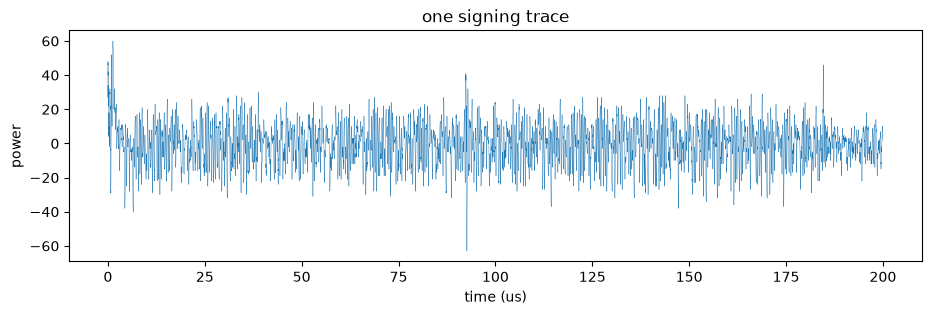

In [2]:
example = np.load('nb_corr_full.npz')['example'].astype(float)
plt.figure(figsize=(11, 3))
plt.plot(np.arange(len(example)) / 1000.0, example, lw=.3)
plt.xlabel('time (us)'); plt.ylabel('power'); plt.title('one signing trace')
plt.show()


## 1b. Where the key leaks

Correlating the power with the secret coefficient marks the two leak points we template:
the **decode** (`|rho|~0.97`) and the **mod-q** step (`|rho|~0.38`).


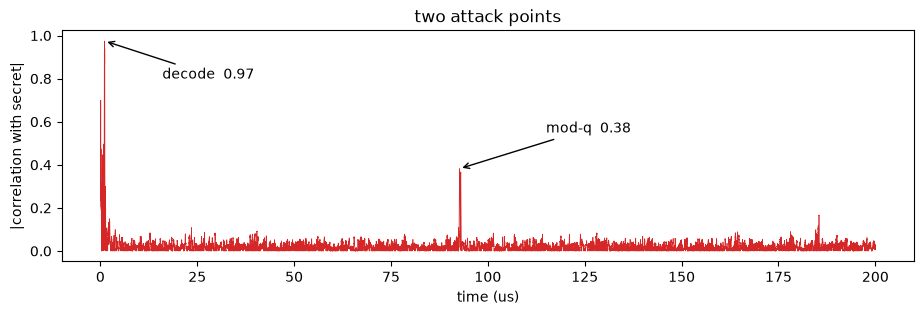

In [3]:
corr = np.load('nb_corr_full.npz')['corr']
plt.figure(figsize=(11, 3))
plt.plot(np.arange(len(corr)) / 1000.0, corr, lw=.5, color='C3')
plt.annotate('decode  0.97', xy=(1.1, corr[1093]), xytext=(16, 0.80), arrowprops=dict(arrowstyle='->'))
plt.annotate('mod-q  0.38', xy=(92.7, corr[92676]), xytext=(115, 0.55), arrowprops=dict(arrowstyle='->'))
plt.xlabel('time (us)'); plt.ylabel('|correlation with secret|'); plt.title('two attack points')
plt.show()


## 2. Attack one coefficient

Each coefficient is measured a few times (here 45 traces) and **averaged** to cut the noise.
We then score that averaged trace against every template and rank the candidate values. The
best score is the prediction; the gap to the runner-up is the confidence.


In [4]:
random.seed(0)                        # fixed so the demo repeats identically

def measure(value, n=45):
    # the attacker measures this coefficient n times and averages to cut the noise
    sample = random.sample(list(traces[value]), n)
    return np.mean(sample, axis=0)

def scores(trace):
    # score the trace against every template; higher score = better match
    normalized = (trace - mu) / sd
    return normalized @ W.T + b

s = scores(measure(f_true[0]))
order = np.argsort(s)[::-1]            # sort candidates, best first

print('candidate  score')
for j in order[:5]:
    print(f'  {candidates[j]:+d}   {s[j]:8.2f}')

best = candidates[order[0]]
confidence = s[order[0]] - s[order[1]]
print(f'\npredicted f[0] = {best:+d}   confidence {confidence:.2f}')


candidate  score
  +2      35.35
  +1      34.56
  +5      32.01
  +4      31.65
  +6      31.49

predicted f[0] = +2   confidence 0.79


## 3. A few more coefficients


In [5]:
for i in range(10):
    s = scores(measure(f_true[i]))
    order = np.argsort(s)[::-1]
    predicted = candidates[order[0]]
    confidence = s[order[0]] - s[order[1]]
    print(f'f[{i:>2}]  predicted {predicted:+d}   (secret {f_true[i]:+d})   confidence {confidence:.2f}')


f[ 0]  predicted +2   (secret +2)   confidence 0.32
f[ 1]  predicted +0   (secret +0)   confidence 3.52
f[ 2]  predicted +1   (secret +1)   confidence 0.41
f[ 3]  predicted -2   (secret -2)   confidence 0.45
f[ 4]  predicted +3   (secret +3)   confidence 2.16
f[ 5]  predicted +5   (secret +5)   confidence 0.20
f[ 6]  predicted -1   (secret -1)   confidence 3.71
f[ 7]  predicted -2   (secret -3)   confidence 0.04
f[ 8]  predicted +0   (secret +0)   confidence 3.78
f[ 9]  predicted +5   (secret +5)   confidence 0.34


## 4. Recover the full key

The template reads every coefficient (~98% correct). We keep the 1030 most-confident reads and
solve the public relation `H*f = g (mod 12289)` for the rest. A Falcon coefficient must be in
**[-15, 15]**, so that bound is our check: if the solved key stays in range, it is correct.


In [6]:
def recover():
    # read every coefficient of f and g, each with a confidence
    reads = []
    for name, key in (('f', f_true), ('g', g_true)):
        for i in range(N):
            s = scores(measure(key[i]))
            order = np.argsort(s)[::-1]
            reads.append((s[order[0]] - s[order[1]], name, i, int(candidates[order[0]])))
    # keep the 1030 most-confident reads and solve H*f = g for the rest
    reads.sort(reverse=True)
    known_f = {i: v for conf, name, i, v in reads[:1030] if name == 'f'}
    known_g = {i: v for conf, name, i, v in reads[:1030] if name == 'g'}
    f_full, g_full = km.solve_completion_fast(h, known_f, known_g)
    f_rec = np.array([km.to_signed(v) for v in f_full])
    g_rec = np.array([km.to_signed(v) for v in g_full])
    return f_rec, g_rec

# the solve needs every kept read correct; if one was wrong the result leaves
# [-15, 15]. That bound is the check: if it fails, re-read and try again.
random.seed(0)                        # deterministic, so this cell always reproduces
for attempt in range(1, 6):
    f_rec, g_rec = recover()
    in_range = bool(np.all(np.abs(f_rec) <= 15) and np.all(np.abs(g_rec) <= 15))
    print(f'attempt {attempt}: coefficients in [-15, 15]? {in_range}')
    if in_range:
        break
    print('   a kept read was wrong - re-reading and retrying')

np.set_printoptions(threshold=np.inf, linewidth=120)
print('recovered f (all', len(f_rec), 'coefficients):'); print(f_rec)
print('\nrecovered g (all', len(g_rec), 'coefficients):'); print(g_rec)
print('\nsecret key recovered :', np.array_equal(f_rec, f_true) and np.array_equal(g_rec, g_true))


attempt 1: coefficients in [-15, 15]? True
recovered f (all 1024 coefficients):
[ 2  0  1 -2  3  5 -1 -3  0  5  0  4 -2  0  3  1 -1  5  0  0 -1 -2  1  4  0  4 -2  1  2  2  0 -5  0  3  2  0  4 -3  1
  5  5  6 -3 -1  1  2 -3  1 -2  0 -5  2 -5  1 -4 -2  2  1 -4 -7  1  1 -4  5  3 -4  3 -4  5  5  5 -4 -1 -4 -3  6  0 -1
  0 -2 -2  2 -1 -1 -1  0  0 -1 -1  1 -1 -1 -2  0  2 -5  1  2  0 -2  3  3 -3  1  1 -6  1 -4  0 -4  2  7 -2 -3 -5 -3  3
  0 -5 -1 -1  2 -1  1  0 -5 -3  4  1  1  0 -5 -1  1  2  3  1  2 -2  4 -3  1 -1  4  0  2 -2  4  3  5 -1  3  2  3  2  1
  4 -8 -1 -2  4  0  2  1  3  3  0  2  0 -1  2  5  3 -2  3 -2 -8 -3  1 -4  1  4  0  1 -1 -7  1 -2  1 -5  1  2  4  1 -4
  0 -5 -5  1  2  1  4  3  2 -5 -2  1 -4 -3 -4 -2  1  4  0 -1 -3  4  1  2 -3 -3  1  0  4 -2 -1 -1  3 -2  2  0  2  4  2
  6  1 -5  1  0 -2  0 -2  1  1  3  2  2 -4 -1 -6  2  0  1  0  1 -6  1  5  1 -1  4  1  1  6  1 -2 -2  3 -5 -1 -2  3 -1
  1 -5 -1  0  0  0  2  1  4 -2  0 -1  4  4 -4 -4  3  3  2 -4 -2 -2 -1 -1 -5 -2 -2 -6  5  5 -2 